In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv('california_housing.csv')

In [3]:
feature_names = ['AveRooms', 'AveBedrms', 'AveOccup']
df_filtered = df[feature_names + ['MedHouseVal']].copy()
df_clean = df_filtered[df_filtered['MedHouseVal'] < 5.0].copy()

In [4]:
X = df_clean[feature_names]
Y = df_clean['MedHouseVal']

In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
X_train_b = np.c_[np.ones((len(X_train_scaled), 1)), X_train_scaled]
X_test_b = np.c_[np.ones((len(X_test_scaled), 1)), X_test_scaled]

In [8]:
Y_train_vec = Y_train.values.reshape(-1, 1)
Y_test_vec = Y_test.values.reshape(-1, 1)

In [9]:
print("Data preprocessing complete!")
print(f"Columns retained: {list(df_clean.columns)}")
print(f"Training set shape: {X_train_b.shape}")
print(f"Test set shape: {X_test_b.shape}")

Data preprocessing complete!
Columns retained: ['AveRooms', 'AveBedrms', 'AveOccup', 'MedHouseVal']
Training set shape: (15718, 4)
Test set shape: (3930, 4)


In [10]:
X_T = X_train_b.T
theta_normal = np.linalg.inv(X_T.dot(X_train_b)).dot(X_T).dot(Y_train_vec)
w0_normal = theta_normal[0][0]

In [11]:
print("--- Normal Equation Parameters ---")
print(f"Intercept (w0): {w0_normal:.4f}")
for name, weight in zip(feature_names, theta_normal[1:]):
    print(f"Weight ({name:<9}): {weight[0]:.4f}")

--- Normal Equation Parameters ---
Intercept (w0): 1.9205
Weight (AveRooms ): 0.5786
Weight (AveBedrms): -0.5505
Weight (AveOccup ): -0.0193


In [25]:
Y_pred_normal = X_test_b.dot(theta_normal)
alpha = 0.01
n_iterations = 1000
m = len(X_train_b)
theta_gd = np.zeros((len(feature_names) + 1, 1))
cost_history = []
for iteration in range(n_iterations):
    predictions = X_train_b.dot(theta_gd)
    cost = (1 / (2 * m)) * np.sum((predictions - Y_train_vec) ** 2)
    cost_history.append(cost)
    gradients = (1 / m) * X_train_b.T.dot(predictions - Y_train_vec)
    theta_gd = theta_gd - alpha * gradients
w0_gd = theta_gd[0][0]

In [26]:
print("--- Gradient Descent Parameters ---")
print(f"Intercept (w0): {w0_gd:.4f}")
for name, weight in zip(feature_names, theta_gd[1:]):
    print(f"Weight ({name:<9}): {weight[0]:.4f}")

--- Gradient Descent Parameters ---
Intercept (w0): 1.9204
Weight (AveRooms ): 0.4451
Weight (AveBedrms): -0.4170
Weight (AveOccup ): -0.0192


In [27]:
# Predictions on Test Set
Y_pred_gd = X_test_b.dot(theta_gd)
mse = mean_squared_error(Y_test_vec, Y_pred_normal)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test_vec, Y_pred_normal)

In [28]:
print("--- Model Performance Metrics ---")
print(f"Mean Squared Error (MSE) : {mse:.4f}")
print(f"Root Mean Squared Error : {rmse:.4f} (~${rmse * 100000:,.2f})")
print(f"R-squared (R²) Score : {r2:.4f}")

--- Model Performance Metrics ---
Mean Squared Error (MSE) : 0.8768
Root Mean Squared Error : 0.9364 (~$93,637.70)
R-squared (R²) Score : 0.0855


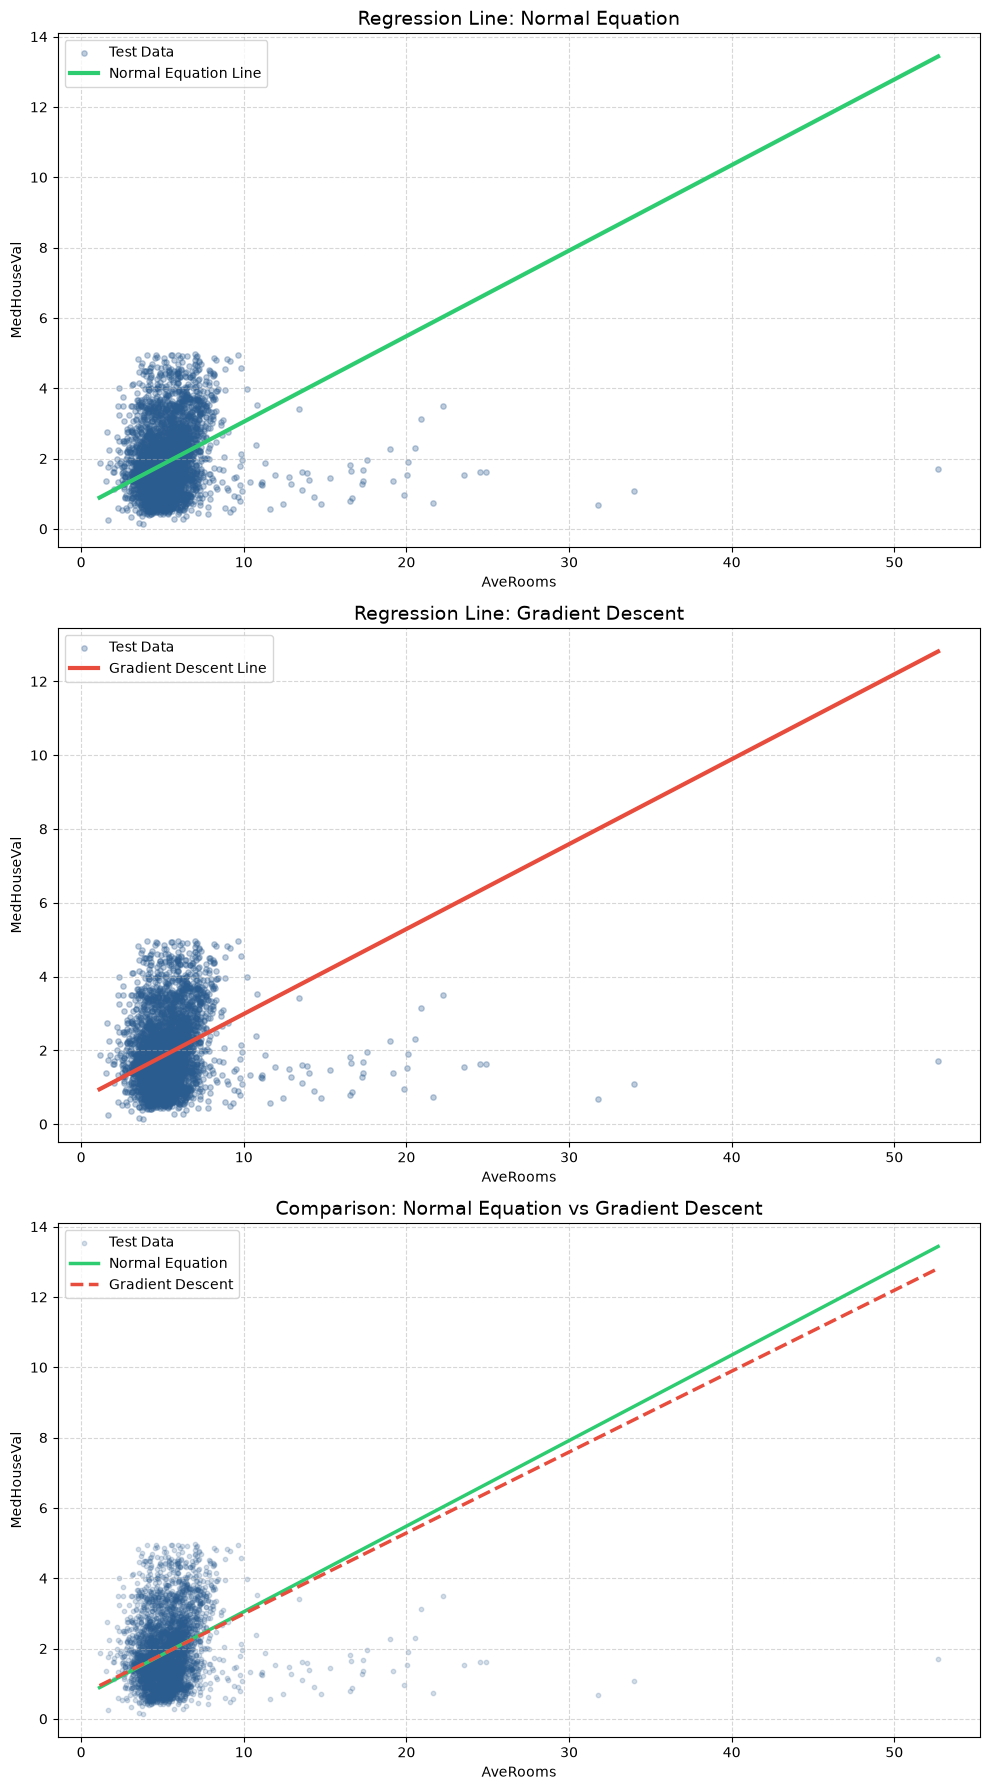

In [29]:
# Create subplots
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# Subplot 1: Normal Equation
axes[0].scatter(X_test['AveRooms'], Y_test, alpha=0.3, color='#2b5c8f', s=15, label='Test Data')
axes[0].plot(x_range_orig, y_plot_normal, color='#2ecc71', linewidth=3, label='Normal Equation Line')
axes[0].set_title('Regression Line: Normal Equation', fontsize=14)
axes[0].set_xlabel('AveRooms')
axes[0].set_ylabel('MedHouseVal')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Gradient Descent
axes[1].scatter(X_test['AveRooms'], Y_test, alpha=0.3, color='#2b5c8f', s=15, label='Test Data')
axes[1].plot(x_range_orig, y_plot_gd, color='#e74c3c', linewidth=3, label='Gradient Descent Line')
axes[1].set_title('Regression Line: Gradient Descent', fontsize=14)
axes[1].set_xlabel('AveRooms')
axes[1].set_ylabel('MedHouseVal')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# Subplot 3: Comparison
axes[2].scatter(X_test['AveRooms'], Y_test, alpha=0.2, color='#2b5c8f', s=10, label='Test Data')
axes[2].plot(x_range_orig, y_plot_normal, color='#2ecc71', linewidth=2.5, linestyle='-', label='Normal Equation')
axes[2].plot(x_range_orig, y_plot_gd, color='#e74c3c', linewidth=2.5, linestyle='--', label='Gradient Descent')
axes[2].set_title('Comparison: Normal Equation vs Gradient Descent', fontsize=14)
axes[2].set_xlabel('AveRooms')
axes[2].set_ylabel('MedHouseVal')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.5)

# Render everything together
plt.tight_layout()
plt.show()